## Derivative Pricing
Haug, E.G. (2007) *The Complete Guide to Option Pricing Formulas*. 2nd edn. New York: McGraw-Hill.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_market_calendars 
import scipy.stats

from math import exp, sqrt, log

### Greek Letters

Denoting the underlying financial contracts value $V(t,S_t)$, underlying financial assets price $S_t$ and corresponding volatility $\sigma$, time to maturity $T$ and riskfree rate $r$

Delta 
$$
\text{Delta} = \frac{\partial V(t,S_t)}{\partial S_t} = \lim_{\Delta S \to 0} \frac{V(t,S_t+\Delta S) - V(t,S_t-\Delta S)}{2\Delta S}
$$

Gamma
$$
\text{Gamma} = \frac{\partial^2 V(t,S_t)}{\partial S_t^2} = \lim_{\Delta S \to 0} \frac{V(t,S_t+\Delta S) - 2 V(t,S_t) + V(t,S_t-\Delta S)}{\Delta S^2}
$$
Vega
$$
\text{Vega} = \frac{\partial V(t,S_t,\sigma)}{\partial \sigma} = \lim_{\Delta \sigma \to 0} \frac{V(t,S_t,\sigma+\Delta \sigma) - V(t,S_t,\sigma - \Delta \sigma)}{\Delta \sigma} \approx V(t,S_t,\sigma+\Delta \sigma) - V(t,S_t,\sigma - \Delta \sigma)
$$
Theta
$$
\text{Theta} = \frac{\partial V(t ,S_t)}{\partial t} = \lim_{\Delta t \to 0} \frac{V(t-\Delta t,S_t) - V(t,S_t) }{\Delta t}
$$
Rho
$$
\text{Rho} = \frac{\partial V(t,S_t,r)}{\partial r} = \lim_{\Delta r \to 0} \frac{V(t,S_t,r+\Delta r) - V(t,S_t,r) }{\Delta r}
$$

Where in practice
$$
\Delta S = 0.005 \times S_t \qquad \Delta \sigma = 0.005 \qquad \Delta t = \frac{1}{244} \qquad \Delta r = 0.001
$$


### Binary Option

Cash or Nothing European Binary Call Option
$$
c = Xe^{-rT}N(d_2)
$$
Cash or Nothing European Binary Put Option
$$
p = Xe^{-rT}N(-d_2)
$$
Asset or Nothing European Binary Call Option
$$
c = S e^{-rT}N(d_1) = S_0 N(d_1)
$$
Asset or Nothing European Binary Put Option
$$
p = S e^{-rT}N(-d_1) = S_0 N(-d_1)
$$

### Futures Option


Black, Fischer, 1976. "The pricing of commodity contracts," Journal of Financial Economics, Elsevier, vol. 3(1-2), pages 167-179. 

Call option on future
$$
c = e^{-rT} \big( F N(d_1) - X N(d_2) \big)
$$
Put option on future
$$
p = e^{-rT} \big( X N(-d_2) - F N(- d_1)  \big)
$$
Where
$$
d_1 = \frac{\ln \big(\frac{F}{X}\big) + \frac{1}{2}\sigma^2 T }{\sigma \sqrt{T}} \qquad d_2 = \frac{\ln\big(\frac{F}{X}\big) - \frac{1}{2}\sigma^2 T }{\sigma \sqrt{T}} = d_1 - \sigma \sqrt{T}
$$

In [ ]:
# Black 1976 Future Option
def Black(F,X,r,sigma,T):

    d1 = (log(F/X) + 1/2 * sigma^2 * T) / (sigma * sqrt(T))
    d2 = (log(F/X) - 1/2 * sigma^2 * T) / (sigma * sqrt(T))

    Call = exp(-r*T) * (F * scipy.stats.norm.cdf(d1) - X * scipy.stats.norm.cdf(d2))
    Put = exp(-r*T) * (F * scipy.stats.norm.cdf(d1) - X * scipy.stats.norm.cdf(d2))

    return Call, Put

### Stock Option



Call Option
$$
c = e^{-qT}SN(d_1) - e^{-rT}XN(d_2) = e^{(b-r)T}SN(d_1) - e^{-rT} XN(d_2)
$$
Put Option
$$
p = e^{-rT}XN(-d_2) - e^{-qT}SN(-d_1)  = e^{-rT} XN(-d_2) - e^{(b-r)T}SN(-d_1) 
$$
Where
$$
d_1 = \frac{\ln \big(\frac{S}{X}\big) + (r - q + \frac{1}{2}\sigma^2) T }{\sigma \sqrt{T}} = \frac{\ln \big(\frac{S}{X}\big) + (b + \frac{1}{2}\sigma^2) T }{\sigma \sqrt{T}}  
$$
$$
d_2 = \frac{\ln \big(\frac{S}{X}\big) + (r - q - \frac{1}{2}\sigma^2) T }{\sigma \sqrt{T}} = \frac{\ln \big(\frac{S}{X}\big) + (b - \frac{1}{2}\sigma^2) T }{\sigma \sqrt{T}} = d_1 - \sigma \sqrt{T}
$$
$$
b = r - q
$$

In [ ]:
# Black Scholes Merton
def BlackScholesMerton(S,X,r,q,sigma,T):

    b = r - q

    d1 = (log(S/X) + (b + 1/2 * sigma^2) * T) / (sigma * sqrt(T))
    d2 = (log(S/X) + (b - 1/2 * sigma^2) * T) / (sigma * sqrt(T))

    Call = exp((b-r)*T) * S * scipy.stats.norm.cdf(d1) - exp(-r*T) * X * scipy.stats.norm.cdf(d2)
    Put = exp(-r*T) * X * scipy.stats.norm.cdf(-d2) - exp((b-r)*T) * S * scipy.stats.norm.cdf(-d1)

    return Call, Put

### Barone Adeis Whaley


Barone-Adesi G, Whaley R E. Efficient Analytic Approximation of American Option Values.(1987) The Journal of Finance, 42, 301-320.

$$
c(S,X,T) = 
\begin{cases}
    c_{\text{BSM}}(S,X,T) + A_2 \big(\frac{S}{S^*}\big)^{q_2} & S < S^* \\
    S - X & S \geq S^*
\end{cases}
$$
Where
$$
A_2 = \frac{S^*}{q_2} \left( 1 - e^{(b-r)T} N(d_1(S^*)) \right) \qquad d_1(S) = \frac{\ln \big(\frac{S}{X}\big) + (b + \frac{1}{2}\sigma^2) T }{\sigma \sqrt{T}}
$$
$$
q_2 = \frac{-(N-1) + \sqrt{(N-1)^2 + \frac{4M}{K}}}{2} \qquad M = \frac{2r}{\sigma^2} \qquad N = \frac{2b}{\sigma^2} \qquad K = 1 - e^{-rT}
$$
Critical Stock Pricing $S^*$ can be found by following
$$
S^* - X = c_{\text{BSM}}(S^*,X,T) + \big( 1 - e^{(b-r)T} N(d_1(S^*))\big) \frac{S^*}{q_2} 
$$
Further denote
$$
h(S^*) = S^* - X - c_{\text{BSM}}(S^*,X,T) - \big( 1 - e^{(b-r)T} N(d_1(S^*))\big) \frac{S^*}{q_2} 
$$
Exploiting Newton Raphson, above can be found. See Chapter 3.1 Espen Huag (2007)
$$
S^{*(i+1)} = S^{*(i)} - \frac{h(S^{*(i)})}{h^{'}(S^{*(i)})}
$$
Straight forward computation gets
$$
h^{'}(S^{*(i)}) = \frac{\partial h(S^*)}{\partial S^*} = 1 - e^{(b-r)T} N(d_1(S^{*(i)})) \big(1 - \frac{1}{q_2}\big) - \frac{1}{q_2}\left(1 - \frac{e^{(b-r)T} n(d_1(S^{*(i)}))}{\sigma \sqrt{T}} \right) 
$$
Where
$$
n(x) = \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{1}{2}x^2\right)
$$
It is further suggested for initial value $S^{*(0)}$ as following 
$$
S^{*(0)} = X + \big( S^*(\infty) - X\big)(1-e^{h_2})
$$
Where
$$
h_2 = -(bT + 2 \sigma \sqrt{T})\left( \frac{X}{S^*(\infty) - X} \right)
$$
Where $S^*(\infty)$ is the critical stock price when time to expiration is infintie
$$
S^*(\infty) = \frac{X}{1-2\big( -(N-1) + \sqrt{(N-1)^2 + 4M} \big)^{-1}}
$$

### Bjerksund Stensland

Bjerksund P, Stensland G. Closed-form approximation of American options[J]. Scandinavian Journal of Management, 1993, 9: S87-S99.

### Binomial Tree


Hull J C, White A D. Efficient procedures for valuing European and American path-dependent options[J]. The Journal of Derivatives, 1993, 1(1): 21-31.

Upward factor and Downward factor are
$$
u = \exp(\sigma \sqrt{\Delta t}) \qquad d = \frac{1}{u} = \exp(-\sigma \sqrt{\Delta t}) 
$$
Risk Neutral probability $p$ is
$$
p = \frac{e^{(r-q)\Delta t} - d}{u-d}
$$
Binomial Tree Option Pricing can be compactly summarised by constructing grids 
$$
0 = t_0 \leq t_1 = \Delta t \leq t_2 = 2 \Delta t \leq ... \leq t_n = n\Delta t = T
$$
Call Option 
$$
c = e^{-rT}\sum^{n}_{i=0} \left( \frac{n!}{i! (n-i)!} \right)p^i (1-p)^{n-i} \max (S u^id^{n-i} - X, 0)
$$
Put Option
$$
p = e^{-rT}\sum^{n}_{i=0} \left( \frac{n!}{i! (n-i)!} \right)p^i (1-p)^{n-i} \max (X - S u^id^{n-i}, 0)
$$

In [ ]:
# Binomial Tree Hull White
# European Call Option
def BinomialTree(S,X,r,q,sigma,T,n):
    # Grid
    dt = T / n
    # Parameters
    u = exp(sigma * sqrt(dt))
    d = exp(- sigma * sqrt(dt))
    p = (exp((r-q)*dt) - d) / (u-d)

    # Constructing Stock Grid
    # Upper Tridiagonal Matrix
    StockTree = np.zeros(shape = (n+1,n+1))
    for i in range(0,n+1):
        for j in range(i,n+1):
            StockTree[i,j] = S * pow(u,j-i) * pow(d,i)

    # Constructing Value Grid
    ValueTree = np.zeros(shape = (n+1,n+1))
    # Terminal Value
    for i in range(0,n+1):
        # European Call
        ValueTree[i,n] = max(StockTree[i,n] - X, 0)

    # Working Backward
    j = n - 1
    while j >= 0:
        for i in range(0,j+1):
            ValueTree[i,j] = exp(-r*dt)*(p*ValueTree[i,j+1] + (1-p)*ValueTree[i+1,j+1])

        # Backward Moving
        j = j - 1
    
    # Returning Value Tree Initial Point
    return ValueTree[0,0]

### Turnbull Wakeman


Turnbull, Stuart M., and Lee Macdonald Wakeman. “A Quick Algorithm for Pricing European Average Options.” Journal of Financial and Quantitative Analysis 26, no. 3 (1991): 377–89.

Arithmetic Averaged European Asian Call Option
$$
c = e^{-rT}\left( S e^{b_A T} N(d_1) - X N(d_2) \right)
$$
Asian Put Option
$$
p = e^{-rT}\left( X N(-d_2) - S e^{b_A T} N(-d_1)\right)
$$
Where
$$
d_1 = \frac{\ln \big(\frac{S}{X}\big) + (b_A + \frac{1}{2}\sigma_A^2) T }{\sigma \sqrt{T}}  \qquad d_2 = d_1 = \frac{\ln \big(\frac{S}{X}\big) + (b_A - \frac{1}{2}\sigma_A^2) T }{\sigma \sqrt{T}} 
$$
Where modified parameters are given as
$$
\sigma_A = \sqrt{\frac{\ln M_2}{T} - 2 b_A} \qquad b_A = \frac{\ln M_1}{T}
$$
$$
M_1 = 
\begin{cases}
1 & b = 0 \\
\frac{e^{bT} - e^{bt_1}}{b(T-t_1)} & b \neq 0
\end{cases}
$$
$$
M_2 = 
\begin{cases}
\frac{2 e^{\sigma^2 T} - 2 e^{\sigma^2 t_1 \big( 1 + \sigma^2 (T-t_1)\big)}}{\sigma^4(T-t_1)^2} & b = 0 \\
\frac{2e^{(2b+ \sigma^2)T}}{(b+\sigma^2)\times (2b+\sigma^2) \times (T-t_1)^2} + \frac{2e^{(2b+\sigma^2)t_1}}{b(T-t_1)^2}\left( \frac{1}{2b+\sigma^2} - \frac{e^{b(T-t_1)}}{b+\sigma^2} \right) & b \neq 0
\end{cases}
$$

### Kemna Vorst


A.G.Z. Kemna, A.C.F. Vorst, A pricing method for options based on average asset values, Journal of Banking & Finance, Volume 14, Issue 1, 1990, Pages 113-129, ISSN 0378-4266

Geometric Averaged European Asian Call Option
$$
c = e^{-rT}\left( S e^{b_A T} N(d_1) - X N(d_2) \right)
$$
Asian Put Option
$$
p = e^{-rT}\left( X N(-d_2) - S e^{b_A T} N(-d_1)\right)
$$
Where
$$
d_1 = \frac{\ln \big(\frac{S}{X}\big) + (b_A + \frac{1}{2}\sigma_A^2) T }{\sigma \sqrt{T}}  \qquad d_2 = d_1 = \frac{\ln \big(\frac{S}{X}\big) + (b_A - \frac{1}{2}\sigma_A^2) T }{\sigma \sqrt{T}} 
$$
$$
\sigma_A = \frac{\sigma}{\sqrt{3}} \qquad b_A = \frac{1}{2}\big( b - \frac{\sigma^2}{6}\big)
$$

### Merton Reiner Rubinstein



Rubinstein M. Breaking down the barriers[J]. Risk, 1991, 4: 28-35.

Merton, Robert C. “Theory of Rational Option Pricing.” The Bell Journal of Economics and Management Science, vol. 4, no. 1, 1973, pp. 141–83. JSTOR.

Notation $S$ being Stock, $X$ being Strike Price, $K$ being Rebate and $H$ being barrier.

Defining Factors as
$$
A = \Phi S e^{(b-r)T} N(\Phi x_1) - \Phi X e^{-rT} N(\Phi x_1 - \Phi \sigma \sqrt{T})
$$
$$
B = \Phi S e^{(b-r)T} N(\Phi x_2) - \Phi X e^{-rT} N(\Phi x_2 - \Phi \sigma \sqrt{T})
$$
$$
C = \Phi S e^{(b-r)T} \big( \frac{H}{S} \big)^{2(\mu + 1)} N(\eta y_1) - \Phi X e^{-rT} \big( \frac{H}{S} \big)^{2\mu} N(\eta y_1 - \eta \sigma \sqrt{T})
$$
$$
D = \Phi S e^{(b-r)T} \big( \frac{H}{S} \big)^{2(\mu + 1)} N(\eta y_2) - \Phi X e^{-rT} \big( \frac{H}{S} \big)^{2\mu} N(\eta y_2 - \eta \sigma \sqrt{T})
$$
$$
E = K e^{-rT}\left(  N(\eta x_2 - \eta \sigma \sqrt{T}) - \big( \frac{H}{S} \big)^{2\mu} N(\eta y_2 - \eta \sigma \sqrt{T})  \right)
$$
$$
F = K \left( \big( \frac{H}{S} \big)^{\mu+\lambda} N(\eta z) + \big( \frac{H}{S} \big)^{\mu-\lambda}  N(\eta z - 2 \eta \lambda \sigma \sqrt{T})  \right)
$$
Where
$$
x_1 = \frac{\ln \big(\frac{S}{X}\big)}{\sigma \sqrt{T}} + (1+\mu)\sigma \sqrt{T} \qquad x_2 = \frac{\ln \big(\frac{S}{H}\big)}{\sigma \sqrt{T}} + (1+\mu)\sigma \sqrt{T}
$$
$$
y_1 = \frac{\ln\big(  \frac{H^2}{SX}  \big)}{\sigma \sqrt{T}} + (1+\mu)\sigma \sqrt{T} \qquad y_2 = \frac{\ln\big(  \frac{H}{S}  \big)}{\sigma \sqrt{T}} + (1+\mu)\sigma \sqrt{T}
$$
$$
z = \frac{\ln\big(  \frac{H}{S}  \big)}{\sigma \sqrt{T}} + \lambda \sigma \sqrt{T} \qquad \mu = \frac{b - \frac{1}{2}\sigma^2}{\sigma^2} \qquad \lambda = \sqrt{\mu^2 + \frac{2r}{\sigma^2}}
$$

Down and In Barrier Call Option with $\eta = 1 \quad \Phi = 1$
$$
c = 
\begin{cases}
C+E & X > H \\
A-B+D+E & X \leq H
\end{cases}
$$

Up and In Barrier Call Option with $\eta = -1 \quad \Phi = 1$
$$
c = 
\begin{cases}
A+E & X > H \\
B-C+D+E & X \leq H
\end{cases}
$$

Down and In Barrier Put Option with $\eta = 1 \quad \Phi = -1$
$$
p = 
\begin{cases}
B-C+D+E & X > H \\
A+E & X \leq H
\end{cases}
$$

Up and Out Barrier Put Option with $\eta = -1 \quad \Phi = -1$
$$
p = 
\begin{cases}
A-B+D+E & X > H \\
C+E & X \leq H
\end{cases}
$$

Down and Out Barrier Call Option with $\eta = 1 \quad \Phi = 1$
$$
c = 
\begin{cases}
A-C+F & X > H \\
B-D+F & X \leq H
\end{cases}
$$

Up and Out Barrier Call Option with $\eta = -1 \quad \Phi = 1$
$$
c = 
\begin{cases}
F & X > H \\
A-B+C-D+F & X \leq H
\end{cases}
$$

Down and Out Barrier Put Option with $\eta = 1 \quad \Phi = -1$
$$
p = 
\begin{cases}
A-B+C-D+F & X > H \\
F & X \leq H
\end{cases}
$$

Up and Out Barrier Put Option with $\eta = -1 \quad \Phi = -1$
$$
p = 
\begin{cases}
B-D+F & X > H \\
A-C+F & X \leq H
\end{cases}
$$

In [ ]:
# Single Barrier European Call Option
def ReinerRubinstein(S,X,H,K,r,q,sigma,T,eta,Phi):
    # Parameter
    b = r - q
    mu = (b - 1/2*sigma**2) / sigma**2
    Lambda = sqrt(mu**2 + 2*r/sigma**2)

    x1 = log(S/X) / (sigma * sqrt(T)) + (1+mu) * sigma * sqrt(T)
    x2 = log(S/H) / (sigma * sqrt(T)) + (1+mu) * sigma * sqrt(T)

    y1 = log(H**2/(S*X)) / (sigma * sqrt(T)) + (1+mu) * sigma * sqrt(T)
    y2 = log(H/S) / (sigma * sqrt(T)) + (1+mu) * sigma * sqrt(T)

    z = log(H/S) / (sigma * sqrt(T)) + Lambda * sigma * sqrt(T)

    # Factors
    A = Phi*S*exp((b-r)*T) * scipy.stats.norm.cdf(Phi*x1) - Phi*X*exp(-r*T) * scipy.stats.norm.cdf(Phi*x1 - Phi*sigma*sqrt(T))
    B = Phi*S*exp((b-r)*T) * scipy.stats.norm.cdf(Phi*x2) - Phi*X*exp(-r*T) * scipy.stats.norm.cdf(Phi*x2 - Phi*sigma*sqrt(T))
    C = Phi*S*exp((b-r)*T) * pow(H/S,2*(mu+1)) * scipy.stats.norm.cdf(eta*y1) - Phi*X*exp(-r*T) * pow(H/S,2*mu) * scipy.stats.norm.cdf(eta*y1 - eta*sigma*sqrt(T))
    D = Phi*S*exp((b-r)*T) * pow(H/S,2*(mu+1)) * scipy.stats.norm.cdf(eta*y2) - Phi*X*exp(-r*T) * pow(H/S,2*mu) * scipy.stats.norm.cdf(eta*y2 - eta*sigma*sqrt(T))
    E = K*exp(-r*T) * (scipy.stats.norm.cdf(eta*x2 - eta*sigma*sqrt(T)) - pow(H/S,2*mu) * scipy.stats.norm.cdf(eta*y2 - eta*sigma*sqrt(T)))
    F = K * (pow(H/S,mu+Lambda) * scipy.stats.norm.cdf(eta*z) + pow(H/S,mu-Lambda) * scipy.stats.norm.cdf(eta*z - 2*eta*Lambda*sigma*sqrt(T)))
        

### European Call Option

Consider Solving Vanilla European Call Option Through Crank Nicolson Numerically Solving Partial Differential Equation

Black Scholes Partial Differential Equation
$$
V_t + (r-q)S V_S + \frac{1}{2} \sigma^2 S^2 V_{SS} - r V =0
$$
Partial Derivative approximations 
$$
\begin{aligned}
V(S,t)
& = V\left(S,t+\frac{1}{2}\Delta t\right)-\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t} +\frac{1}{8}(\Delta t)^2
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t^2}
+O(\|\Delta t\|^3)
\end{aligned}
$$
And
$$
\begin{aligned}
V(S,t+\Delta t)
&  = V\left(S,t+\frac{1}{2}\Delta t\right)
+\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t} +\frac{1}{8}(\Delta t)^2
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t^2}
+O(\|\Delta t\|^3)
\end{aligned}
$$

Therefore 

$$
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t}
=\frac{V(S,t+\Delta t)-V(S,t)}{\Delta t}
+O(\|\Delta t\|^2)
$$

Because

$$
\frac{\partial V(S,t)}{\partial S} = 
\frac{V(S+\Delta S,t)-V(S-\Delta S,t)}
{2\Delta S}+O(\|\Delta S\|^2)
$$

$$
\frac{\partial V(S,t+\Delta t)}{\partial S} =
\frac{
V(S+\Delta S,t+\Delta t)-V(S-\Delta S,t+\Delta t)
}{2\Delta S}
+O(\|\Delta S\|^2)
$$
And

$$
\begin{aligned}
\frac{\partial V(S,t)}{\partial S} + \frac{\partial V(S,t+\Delta t)}{\partial S} = \frac{
V(S+\Delta S,t)-V(S-\Delta S,t)
+V(S+\Delta S,t+\Delta t)-V(S-\Delta S,t+\Delta t)
}{2\Delta S} +O(\|\Delta S\|^2)
\end{aligned}
$$

Restating that

$$
\begin{aligned}
V(S,t)
& = V\left(S,t+\frac{1}{2}\Delta t\right)-\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t} +\frac{1}{8}(\Delta t)^2
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t^2}
+O(\|\Delta t\|^3)
\end{aligned}
$$
And
$$
\begin{aligned}
V(S,t+\Delta t)
&  = V\left(S,t+\frac{1}{2}\Delta t\right)
+\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t} +\frac{1}{8}(\Delta t)^2
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial t^2}
+O(\|\Delta t\|^3)
\end{aligned}
$$

Differentiating with respect to $S$

$$
\begin{aligned}
\frac{\partial}{\partial S}V(S,t)
=\frac{\partial}{\partial S}
V\left(S,t+\frac{1}{2}\Delta t\right) -\frac{1}{2}\Delta t
\frac{\partial}{\partial S}
\left(
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t}
\right)
+O(\|\Delta t\|^2)
\end{aligned}
$$

$$
\begin{aligned}
\frac{\partial}{\partial S}V(S,t+\Delta t)=
\frac{\partial}{\partial S}
V\left(S,t+\frac{1}{2}\Delta t\right)
+\frac{1}{2}\Delta t
\frac{\partial}{\partial S}
\left(
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t}
\right)
+O(\|\Delta t\|^2)
\end{aligned}
$$

Adding up

$$
\frac{\partial V(S,t)}{\partial S} + \frac{\partial V(S,t+\Delta t)}{\partial S} = 2\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S}+O(\|\Delta t\|^2)
$$

Replacing left hand side

$$
2 \frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}{\partial S} + O(\|\Delta t\|^2) =
\frac{ V(S+\Delta S,t)-V(S-\Delta S,t)
+V(S+\Delta S,t+\Delta t)-V(S-\Delta S,t+\Delta t)
}{2\Delta S}
$$
Finally
$$
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S}=
\frac{V(S+\Delta S,t)-V(S-\Delta S,t)
+V(S+\Delta S,t+\Delta t)
-V(S-\Delta S,t+\Delta t)}{4\Delta S}  +O(\|\Delta S\|^2+\|\Delta t\|^2)
$$

As for second order finite differencing

$$
\frac{\partial^2 V(S,t)}{\partial S^2}= \frac{
V(S+\Delta S,t)-2V(S,t)+V(S-\Delta S,t)
}{(\Delta S)^2}
+O(\|\Delta S\|^2)
$$

$$
\frac{\partial^2 V(S,t+\Delta t)}{\partial S^2}=
\frac{
V(S+\Delta S,t+\Delta t)
-2V(S,t+\Delta t)
+V(S-\Delta S,t+\Delta t)
}{(\Delta S)^2}
+O(\|\Delta S\|^2)
$$

$$
\begin{aligned}
\frac{\partial^2 V(S,t)}{\partial S^2}
+
\frac{\partial^2 V(S,t+\Delta t)}{\partial S^2} =
\frac{V(S+\Delta S,t)-2V(S,t)+V(S-\Delta S,t) +V(S+\Delta S,t+\Delta t)
-2V(S,t+\Delta t)
+V(S-\Delta S,t+\Delta t)}{(\Delta S)^2}
+O(\|\Delta S\|^2)
\end{aligned}
$$

Again Twice Differentiating with respect to $S$


$$
\frac{\partial^2 V(S,t)}{\partial S^2} =
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S^2}-\frac{1}{2}\Delta t
\frac{\partial^3 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t\,\partial S^2}
+O(\|\Delta t\|^2)
$$

$$
\begin{aligned}
\frac{\partial^2 V(S,t+\Delta t)}{\partial S^2}=
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S^2}
+\frac{1}{2}\Delta t
\frac{\partial^3 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t\,\partial S^2}
+O(\|\Delta t\|^2)
\end{aligned}
$$

Adding up

$$
\frac{\partial^2 V(S,t)}{\partial S^2} +
\frac{\partial^2 V(S,t+\Delta t)}{\partial S^2} =
2\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S^2}
+O(\|\Delta t\|^2)
$$

Replacing left hand side with above

$$
\begin{aligned}
2\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S^2}
+O((\Delta t)^2) = 
\frac{V(S+\Delta S,t)-2V(S,t)+V(S-\Delta S,t)
+V(S+\Delta S,t+\Delta t)
-2V(S,t+\Delta t)
+V(S-\Delta S,t+\Delta t)}{(\Delta S)^2} +O(\|\Delta S\|^2)
\end{aligned}
$$

Eventually
$$
\begin{aligned}
\frac{\partial^2 V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial S^2} = 
\frac{V(S+\Delta S,t)-2V(S,t)+V(S-\Delta S,t)+V(S+\Delta S,t+\Delta t)
-2V(S,t+\Delta t)
+V(S-\Delta S,t+\Delta t)}{2(\Delta S)^2} +O(\|\Delta S\|^2+\|\Delta t\|^2)
\end{aligned}
$$

The last one is midpoint averaging
$$
\begin{aligned}
V(S,t)
={}&
V\left(S,t+\frac{1}{2}\Delta t\right)
-\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t}
+O(\|\Delta t\|^2)
\end{aligned}
$$

$$
\begin{aligned}
V(S,t+\Delta t)
={}&
V\left(S,t+\frac{1}{2}\Delta t\right)
+\frac{1}{2}\Delta t
\frac{\partial V\left(S,t+\frac{1}{2}\Delta t\right)}
{\partial t}
+O(\|\Delta t\|^2)
\end{aligned}
$$

$$
V\left(S,t+\frac{1}{2}\Delta t\right)
=\frac{1}{2}
\big(
V(S,t)+V(S,t+\Delta t)
\big)
+O(\|\Delta t\|^2)
$$



Consider Partition on Stock $S$ and Time $T$
$$
S_j = j \times \Delta S \qquad t_i = i \times \Delta t
$$
Where
$$
\Delta S = \frac{S_{\text{max}}}{\text{jMax}} \qquad \Delta t = \frac{T}{\text{iMax}}
$$
Abbreviating 
$$
V^i_j = V(S = j\times \Delta S, t = i \times \Delta t)
$$
Above approximations are
$$
V_t = \frac{V^{i+1}_j - V^i_j}{\Delta t}
$$
$$
V_S = \frac{V^i_{j+1} - V^i_{j-1} + V^{i+1}_{j+1} - V^{i+1}_{j-1}}{4\Delta S}
$$
And
$$
V_{SS} = \frac{V^i_{j+1} - 2 V^i_j + V^i_{j-1} + V^{i+1}_{j+1} - 2V^{i+1}_{j} + V^{i+1}_{j-1}}{2\Delta S^2}
$$
Substituting to Black Scholes PDE
$$
\left( -\frac{1}{4}j (r-q) + \frac{1}{4}j^2 \sigma^2  \right)V^i_{j-1} + \left( -\frac{1}{\Delta t} - \frac{r}{2} -\frac{1}{2}j^2\sigma^2 \right) V^i_j + \left( \frac{1}{4}j (r-q) + \frac{1}{4}j^2 \sigma^2  \right)V^i_{j+1} = \left( \frac{1}{4}j (r-q) - \frac{1}{4}j^2 \sigma^2  \right)V^{i+1}_{j-1} + \left(- \frac{1}{\Delta t} + \frac{r}{2} +\frac{1}{2}j^2\sigma^2 \right) V^{i+1}_j + \left( -\frac{1}{4}j (r-q) - \frac{1}{4}j^2 \sigma^2  \right)V^{i+1}_{j+1}
$$
Which can be further abbreviated as
$$
\boldsymbol{A} \boldsymbol{V}^i = \boldsymbol{d}^{i+1}
$$
That is
$$
\begin{pmatrix} 
b_0 & c_0 & 0 & 0 & 0 & 0 & ... & 0 & 0 & 0 \\
a_1 & b_1 & c_1 & 0 & 0 & 0 & ... & 0 & 0 & 0 \\
0 & a_2 & b_2 & c_2 & 0 & 0 & ... & 0 & 0 & 0 \\
0 & 0 & a_3 & b_3 & c_3 & 0 & ... & 0 & 0 & 0 \\
... & ... & ... & ... & ... & ... & ... & ... & ... & ... \\
... & ... & ... & ... & a_j & b_j & c_j & ... & ... & ... \\
... & ... & ... & ... & ... & ... & ... & ... & ... & ... \\
0 & 0 & 0 & 0 & 0 & 0 & ... & a_{\text{jMax}-1} & b_{\text{jMax}-1} & c_{\text{jMax}-1} \\
0 & 0 & 0 & 0 & 0 & 0 & ... & 0 & a_{\text{jMax}} & b_{\text{jMax}} \\
\end{pmatrix}
\begin{pmatrix}
V_0^i\\V_1^i\\V_2^i\\V_3^i\\...\\...\\V_{\text{jMax}-1}^i\\V_{\text{jMax}}^i
\end{pmatrix}=
\begin{pmatrix}
d_0^{i+1}\\d_1^{i+1}\\d_2^{i+1}\\d_3^{i+1}\\...\\...\\d_{\text{jMax}-1}^{i+1}\\d_{\text{jMax}}^{i+1}
\end{pmatrix}
$$
Where
$$
\boldsymbol{A} \in \mathbb{R}^{(\text{jMax}+1) \times (\text{jMax}+1)} \quad \boldsymbol{V}^i =  \in \mathbb{R}^{(\text{jMax}+1)} \quad \boldsymbol{d}^{i+1} =  \in \mathbb{R}^{(\text{jMax}+1)}
$$

Consider an European Call Option, the Terminal Value at expiry 
$$
V(S_j,T) = \max (S_j - X, 0)
$$
Boundard Condition are stated as following.

Conisder $S_j = 0\quad j = 0$
$$
V(S_0,t_i) = 0
$$

Conisder $S_{\text{jMax}} = S_{\max} \quad j = \text{jMax}$
$$
V(S_{\text{jMax}},t_i) = S_{\text{jMax}} e^{-q(T-i\Delta t)} - X e^{-r(T-i\Delta t)}
$$

Otherwise, for an European Put Option, Similarly
$$
V(S_j,T) = \max (X - S_j, 0)
$$

Conisder $S_j = 0\quad j = 0$
$$
V(S_0,t_i) = X e^{-r(T-i\Delta t)}
$$

Conisder $S_{\text{jMax}} = S_{\max} \quad j = \text{jMax}$
$$
V(S_{\text{jMax}},t_i) = 0
$$

Closely, Knowing that at Boundary $j = 0$
$$
b_0 V_0^i + c_0 V^i_1 = d^{i+1}_0
$$
To Closely mimick the Boundary Condition of that of an European Call Option, Solving for 
$$
b_0 = 1.0 \qquad c_0 = 0.0 \qquad d^{i+1}_0 = 0.0
$$

As for Boundary $j = \text{jMax}$
$$
a_{\text{jMax}} V^i_{\text{jMax} - 1} + b_{\text{jMax}} V^i_{\text{jMax}} = d^{i+1}_{\text{jMax}}
$$
Similar arguement
$$
a_{\text{jMax}} = 0.0 \qquad b_{\text{jMax}} = 1.0 \qquad d^{i+1}_{\text{jMax}} = S_\text{jMax} e^{-q(T-i\Delta t)} - X e^{-r(T-i\Delta t)}
$$

Whatever Intermediates for $1 \leq j \leq \text{jMax} - 1$
$$
a_j V^i_{j-1} + b_j V^i_{j} + c_j V^i_{j+1} = d^{i+1}_j
$$

A Breif Introduction on Thomas Solver for the tridiagonal system

$$
a_j V_{j-1} + b_j V_j + c_j V_{j+1} = d_j \qquad 0 \leq j \leq \text{jMax}
$$

with $a_0 = 0$ and $c_{\text{jMax}} = 0$.

$$
c_j^{\prime} =
\begin{cases}
\dfrac{c_0}{b_0} & j = 0 \\[10pt]
\dfrac{c_j}{b_j - a_j c_{j-1}^{\prime}} & j = 1, 2, \dots, \text{jMax} - 1 \\[10pt]
0 & j = \text{jMax}
\end{cases}
$$

$$
d_j^{\prime} =
\begin{cases}
\dfrac{d_0}{b_0} & j = 0 \\[10pt]
\dfrac{d_j - a_j d_{j-1}^{\prime}}{b_j - a_j c_{j-1}^{\prime}} & j = 1, 2, \dots, \text{jMax}
\end{cases}
$$

Eventually Solving for

$$
V_j =
\begin{cases}
d_{\text{jMax}}^{\prime} & j = \text{jMax} \\[10pt]
d_j^{\prime} - c_j^{\prime} V_{j+1} & j = \text{jMax} - 1, \dots, 1, 0
\end{cases}
$$

In [ ]:
# Crank Nicolson Solving European Call Option
def CrankNicolsonEuropeanCall(iMax,jMax,r,q,sigma,X,T,SmaxFactor = 2.0):

    # Computing Smax 
    Smax = SmaxFactor * X

    dS = Smax / jMax
    dt = T / iMax

    # Calculating Grid Sequences
    t = np.zeros(shape = (iMax+1))
    S = np.zeros(shape = (jMax+1))
    for j in range(0,jMax+1):
        S[j] = j * dS
    for i in range(0,iMax+1):
        t[i] = i * dt
        
    # Allocating Storage for Results and Intermediates
    ForwardValue = np.zeros(shape = (jMax+1))
    BackwardValue = np.zeros(shape = (jMax+1))

    # Computing Terminal Value 
    for j in range(0,jMax+1):
        ForwardValue[j] = max(S[j]-X,0)

        # Allocating Storeage for Matrix A See Above
    A = np.zeros(shape = (jMax+1,jMax+1))
    
    # Enforcing Boundary Condition at S = 0
    # b_0 V_0 + c_0 V_1 = d_0
    # b_0
    A[0,0] = 1.0
    # c_0
    A[0,1] = 0.0

    # Setting Up Intermediates Values for 1 \leq j \leq jMax
    # a_j V_{j-1} + b_j V_j + c_j V_{j+1} = d^{i+1}
    for j in range(1,jMax):
        # a_j
        A[j,j-1] = -1/4*j*(r-q) + 1/4*j**2*sigma**2
        # b_j
        A[j,j] = - 1/dt - r/2 - 1/2*j**2*sigma**2
        # c_j
        A[j,j+1] = 1/4*j*(r-q) + 1/4*j**2*sigma**2

    # Enforcing Boundary Condition at S = Smax
    # a_jMax V_{jMax-1} + b_jMax V_jMax = d_jMax
    # a_jMax
    A[jMax,jMax-1] = 0.0
    # b_jMax
    A[jMax,jMax] = 1.0

    # Allocating Storeage for Vector d See Above
    d = np.zeros(shape = jMax+1)

    # Solving Backward Step Through Time
    for i in range(iMax-1,-1,-1):
        # Boundary Condition S = 0
        # d^{i+1}_0
        d[0] = 0
        for j in range(1,jMax):
            # d^{i+1}_j 
            d[j] = (1/4*j*(r-q) - 1/4*j**2*sigma**2) * ForwardValue[j-1] + (- 1/dt+r/2+1/2*j**2*sigma**2) * ForwardValue[j] + (-1/4*j*(r-q)-1/4*j**2*sigma**2) * ForwardValue[j+1]
        # Boundary Condition S = Smax
        # d^{i+1}_{jMax}
        d[jMax] = jMax*dS*exp(-q*(T-i*dt)) - X*exp(-r*(T-i*dt))

        # Thomas Solver Solving for A V^i = d^{i+1}
        cPrime = np.zeros(shape = jMax+1)
        dPrime = np.zeros(shape = jMax+1)
        
        # c' = c_0/b_0
        cPrime[0] = A[0,1]/A[0,0] 
        # d' = d_0 / b_0
        dPrime[0] = d[0] / A[0,0]
        for j in range(1,jMax):
            # c' = c_j / (b_j - a_j*c'_{j-1})
            cDenominator = A[j,j] - A[j,j-1]*cPrime[j-1]
            cPrime[j] = A[j,j+1] / cDenominator
            
            # d_j - a_j*d'_{j-1}
            dNumerator = d[j] - A[j,j-1]*dPrime[j-1]
            # b_j - a_j*c'_{j-1}
            dDenominator = A[j,j] - A[j,j-1]*cPrime[j-1]
            dPrime[j] = dNumerator / dDenominator

        # d_j - a_j*d'_{j-1}
        dNumerator = d[jMax] - A[jMax,jMax-1]*dPrime[jMax-1] 
        # b_j - a_j*c'_{j-1}
        dDenominator = A[jMax,jMax] - A[jMax,jMax]*cPrime[jMax-1]
        dPrime[jMax] = dNumerator / dDenominator
        
        # Solving for the results through Back Substitution and Storing it in Backward Value
        BackwardValue[jMax] = dPrime[jMax]
        for j in range(jMax-1,-1,-1):
            # V_j = d'_j - c'_j V_{j+1}
            BackwardValue[j] = dPrime[j] - cPrime[j] * BackwardValue[j+1]

        # Moving Onward to Next Iteration Backward
        ForwardValue = np.copy(BackwardValue)

    # Eventually 
    return S, BackwardValue

### Accumulator



Notation $S_{t_i}$ being Stock Price on Exercisable Date $t_i$, $X_i$ being Strike Price on Date $t_i$ and Barrier Price $B_i$ on Date $t_i$. It is generally the case that $K_i \leq B_i$ for Accumulator while $K_i \geq B_i$ for Decumulator.

Payoff function $g(S_{t_i})$ for accumulator is given as
$$
g(S_{t_i}) = 
\begin{cases}
A_{\text{put}} \times (S_{t_i} - X) & S_{t_i} \leq X_i \\
A_{\text{call}} \times (S_{t_i} - X) / \text{Coupon} & X_i < S_{t_i} < B_i \\
0 &  S_{t_i} \geq B_i
\end{cases}
$$
Alternatively, payoff function of decumulator is
$$
g(S_{t_i}) = 
\begin{cases}
0 & S_{t_i} \leq B_i \\
A_{\text{put}} \times (X - S_{t_i}) / \text{Coupon} & B_i < S_{t_i} < X_i \\
A_{\text{call}} \times (X - S_{t_i}) &  S_{t_i} \geq X_i
\end{cases}
$$

Generally speaking, assuming stock price $S_t$ follows Geometric Brownian Motion
$$
dS_t = (r-q) S_t dt + \sigma S_t dW_t^\mathbb{Q}
$$
Above SDE possesses closed form solution 
$$
S^{(i)}_{t+ \Delta t} = S^{(i)}_t \exp \left( (r-q-\frac{1}{2}\sigma^2)\Delta t + \sigma \sqrt{\Delta t} \epsilon_i \right) \qquad \epsilon_i \sim N(0,1)
$$
Euler Maruyama discresiation
$$
S^{(i)}_{t+ \Delta t} = (r-q) S^{(i)}_t \Delta t + \sigma S^{(i)}_t \sqrt{\Delta t} \epsilon_i \qquad \epsilon_i \sim N(0,1)
$$


Consider following contracts on Accumulator, which has an underlying assets of 000905.SH.

Starting on 2023/02/01, expiring on 2024/02/01. 

Initial Stock Price $S_{t_0} = 12800$, holding $1,000$ contracts. 

Strike Price $X = 90\%$. Knock Out Barrier $B_{\text{KO}} = 105\%$. 

Knock Out Termination = FALSE, Coupon = 0, Call factor $A_{\text{call}} = 1$, Put factor $A_{\text{put}} = 2$.

Knock Out Date Observation 
$$
\{2023/03/01,2023/04/03, 2023/05/04,2023/06/01,2023/07/03,2023/08/01,2023/09/01,2023/10/09,2023/11/01,2023/12/01,2024/01/02,2024/02/01\}
$$

Daily Settled.

Riskless Interest Rate $r = 3%$, Continously Compounded Dividend Rate $q = 3.5%$, Volaitlity $\sigma = 0.3$.

In [31]:
# Monte Carlo Simulation Pricing Accumulator
def AccumulatorMonteCarlo(S,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus):

    # SHANGHAI STOCK EXCHANGE
    MarketCalendar = pandas_market_calendars.get_calendar('SSE')  
    
    # Calculating Annualised Maturity
    TradingDays = MarketCalendar.valid_days(start_date = Date[0], end_date = Date[-1])
    
    TradingDaysCount = len(TradingDays) - 1
    NaturalDaysCount = (TradingDays[-1] - TradingDays[0]).days
    TradingDenominator = 244
    ActualDenominator = 365
    
    Maturity = TradingDenominator / TradingDenominator
    T = NaturalDaysCount / ActualDenominator

    # Trading Time dt
    dt = np.zeros(shape = len(Date)-1)
    # Discounting Time Dt
    Dt = np.zeros(shape = len(Date)-1)
    for i in range(0,len(Date)-1):
        # Calculate Trading Days Count Between Each Knock Out Observation
        dt[i] = (len(MarketCalendar.valid_days(start_date = Date[i], end_date = Date[i+1])) - 1) / TradingDenominator
        # Calculate Calendar Days Count Between Each Knock Out Observation
        Dt[i] = (pd.Timestamp(Date[i+1]) - pd.Timestamp(Date[i])).days / ActualDenominator
    
    # Monte Carlo Stock Price Simulation
    Row = Path
    Column = len(Date) - 1 + 1
    Stock = np.zeros(shape = (Row, Column))
    # Initialising Stock Price 
    Stock[:, 0] = S
    
    # Randomly Spawn Normal Numbers Matrix
    epsilon = np.random.normal(loc=0, scale=1,size=(Row,Column-1))
    for j in range(0,Column-1):
        # Geometric Brownian Motion
        Stock[:,j+1] = Stock[:,j]*np.exp((r-q-1/2*sigma**2) * dt[j] + sigma*sqrt(dt[j])*epsilon[:,j])

    # Accumulator Payoff Structure
    # Initialising Payoff Matrix
    Payoff = np.zeros(shape = (Row,Column - 1))

    # Accumulator Payoff Structure
    for i in range(0,Row):
        for j in range(0,Column - 1):
            # Payoff Function
            if Stock[i,j+1] <= X:
                Payoff[i,j] = Aput * (Stock[i,j+1] - X)
            elif X < Stock[i,j+1] < B:
                if CouponStatus:
                    Payoff[i,j] = Coupon
                else:
                    Payoff[i,j] = Acall * (Stock[i,j+1] - X)
            elif Stock[i,j+1] >= B:
                # Barrier Triggered While UnTerminated
                Payoff[i,j] = 0
                # Barrier Triggered While Terminated
                if Termination:
                    break
    # Discounting Payoff 
    DiscountedValue = np.zeros(shape = Row)

    for i in range(0,Row):
        # For Each Possible Path 
        DiscountedPayoff = 0
        for j in range(0,Column - 1):
            # Discounting
            DiscountedPayoff = DiscountedPayoff + Payoff[i,j] * exp(-r*np.sum(Dt[0:j+1]))
        # After Completion of Each Possible Path
        DiscountedValue[i] = DiscountedPayoff
        
    # Accumulator
    Accumulator = np.mean(DiscountedValue)

    return(Accumulator)

In [32]:
# Parameters
S = 12800
X = S * 0.9
B = S * 1.05
Acall = 1
Aput = 2
Termination = False
r = 0.03
q = 0.035 
sigma = 0.3
Coupon = 0.2
CouponStatus = False
Path = 1000000

# Customising Knock Out Observation Date
Date = pd.to_datetime(["2023-02-01","2023-03-01","2023-04-03","2023-05-04","2023-06-01","2023-07-03","2023-08-01","2023-09-01","2023-10-09","2023-11-01","2023-12-01","2024-01-02","2024-02-01"])

Accumulator = AccumulatorMonteCarlo(S,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
print(Accumulator*1000)

-9063235.536783477


In [ ]:
# Greeks Letter

# See Definition Above
Repetition = 100
dS = 0.005 * S
dsigma = 0.005
dt = 1/244
dr = 0.001

# Delta 
Delta = np.zeros(shape=(Repetition))
# Gamma
Gamma = np.zeros(shape=(Repetition))
# Vega
Vega = np.zeros(shape=(Repetition))
# Theta
Theta = np.zeros(shape=(Repetition))
# Rho
Rho = np.zeros(shape=(Repetition))

# Common Elements
CenteredValue = np.zeros(shape=(Repetition))

for i in range(0,Repetition):

    # Delta Gamma

    # Computing Upward Stock Accumulator Price
    UpwardValue = AccumulatorMonteCarlo(S+dS,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Computing Downward Stock Accumulator Price
    DownwardValue = AccumulatorMonteCarlo(S-dS,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Centered Centered Stock Accumulator Price
    CenteredValue = AccumulatorMonteCarlo(S,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    
    # Calculating Finite Differencing First Order
    Delta[i] = (UpwardValue - DownwardValue)/(2*dS)
    # Calculating Second Order Finite Differencing
    Gamma[i] = (UpwardValue - 2*CenteredValue + DownwardValue)/(dS**2)

    # Vega

    # Computing Upward Sigma Accumulator Price
    UpwardValue = AccumulatorMonteCarlo(S,X,B,r,q,sigma+dsigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Computing Downward Sigma Accumulator Price
    DownwardValue = AccumulatorMonteCarlo(S,X,B,r,q,sigma-dsigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Calculating First Order Finite Differencing 
    Vega[i] = (UpwardValue - DownwardValue)/(2*dsigma)

    # Theta

    # Computing Downward Time Accumulator Price
    ForwardShiftedDate = Date - pd.Timedelta(days = 1)
    DownwardValue = AccumulatorMonteCarlo(S,X,B,r,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Calculating First Order Finite Differencing 
    Theta[i] = (DownwardValue - CenteredValue)/dt

    # Rho

    # Computing Upward Riskfree Accumulator Price
    UpwardValue = AccumulatorMonteCarlo(S,X,B,r+dr,q,sigma,Coupon,Acall,Aput,Date,Path,Termination,CouponStatus)
    # Calculating First Order Finite Differencing 
    Rho[i] = (UpwardValue - CenteredValue)/dr

# Reporting Greeks Letters
Greek = pd.DataFrame(
    {
        "Greek":["Delta", "Gamma", "Vega", "Theta", "Rho"],
        "Mean":[np.mean(Delta),np.mean(Gamma),np.mean(Vega),np.mean(Theta),np.mean(Rho)],
        "Std":[np.std(Delta),np.std(Gamma),np.std(Vega),np.std(Theta),np.std(Rho)]
    }
)
print(Greek.round(4))

### Autocallable Structure Notes



Payoff Structure of Autocallable Structure Notes are quite sophisticated. Following are elaboration on classical autocallable snowball option traded in China mainland.

See the following parameters and notations, with brief explanation attached. 

Notional value $N$, participatory rate $P$, coupon rate $r^{\text{KO}}$ and $r^{\text{Maturity}}$ represents Knock Out and Maturity Status respectively. Once Knock In, strike praice $X = X^{\text{KI}}$. Mismatched Knock In Observation Date $t^{\text{KI}}_a$ and Knock Out Observation Date $t^{\text{KO}}_b$ are further allocated as Knock In Date Set $\boldsymbol{I} = \{ t^{\text{KI}}_1, ... , t^{\text{KI}}_a, ..., t^{\text{KI}}_m \}$ and Knock Out Date Set $\boldsymbol{O} = \{ t^{\text{KO}}_1, ... , t^{\text{KO}}_b, ..., t^{\text{KO}}_n \}$. Remeber that these sets are highly customisable. Further suppose that set $| \boldsymbol{I} | = m$ and $| \boldsymbol{O} | = n$. 

The payoff structure $g(S_t)$ can be further categorsied into 3 distinctive situations. 

Once knock out, the contracts are voided. Defining following through assuming that Up and Out barrier $B^{\text{KO}}_i$
$$
\tau^{\text{KO}} = \inf \left( t^{\text{KO}}_b \in \boldsymbol{O} \mid S_{t^{\text{KO}}_b} \geq B^{\text{KO}}_b \quad \forall b = 1,..., n \right)
$$
Defining Knock In Status $\text{KI}_t$
$$
\text{KI}_t = \mathbb{I}\left(\exists \quad t^{\text{KI}}_b \in \boldsymbol{I}; \quad t^{\text{KI}}_b \leq t \mid S_{t^{\text{KI}}_b} \geq B^{\text{KI}}_b \quad \forall b \quad \text{s.t.} \quad 
t^{\text{KI}}_b \leq t \right)
$$

On knocked out date, the contract generally gives out coupon discounted by given period.
$$
g(S_t) = N  P  \times \tau^{\text{KO}}  r^{\text{KO}}
$$
If Stock Price had never knocked out, the Short Selling Put Options are converted through, and further assuming Down and In barrier $B^{\text{KI}}_j$, spawning a strike price $X^{\text{KO}}$. The payoff is now
$$
g(S_t) = - 1 \times \frac{N}{S_{t_0}} P \times  \max(X-S_T, 0)
$$
The perks of this contract is that, if Stock Price had neither knocked out nor knocked in, it converts to a zero coupon bond for 
$$
g(S_t) = N P  \times T r^{\text{Maturity}}
$$
The payoff structure $g(S_t)$ can be written compactly as
$$
g(S_t) =
\begin{cases}
N + N  P  \tau^{\text{KO}}  r^{\text{KO}} & \tau^{\text{KO}} < +\infty \\[7pt]
N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) & \tau^{\text{KO}} = +\infty \quad \text{and} \quad \text{KI}_t = 1 \\[7pt]
N + N  P  T r^{\text{Maturity}} & \tau^{\text{KO}} = +\infty \quad \text{and} \quad \text{KI}_t = 0
\end{cases}
$$
For Monte Carlo Path
$$
S^{(i)}_{t+ \Delta t} = S^{(i)}_t \exp \left( (r-q-\frac{1}{2}\sigma^2)\Delta t + \sigma \sqrt{\Delta t} \epsilon_i \right) \qquad \epsilon_i \sim N(0,1)
$$

Consider European SnowBall Option anchorred on the underlying assets 000905.SH, starts on 2023-01-18 and ends on 2025-01-17.

Initial Stock Price $S_{t_0} = 12800$, Notional amount $N = 10000000$, Strike Price $X^{\text{KO}} = 100 \% \times S_{t_0}$, Knock Out Barrier $B^{\text{KO}} = 100\% \times S_{t_0}$ and Knock In Barrier $B^{\text{KI}} = 80\% \times S_{t_0}$.

Prepayment Ratio 100%, Principal Protection Ratio 0%, Discounting Rate on Prepayment is 3%, Participatory Rate $P = 100\%$

Knock In Observation Date is daily excerisable, Knock Out Observation Date are
$$
\{ 2023/04/17,2023/05/17,2023/06/19,2023/07/17,2023/08/17,2023/09/18,2023/10/17,2023/11/17,2023/12/18,2024/01/17,2024/02/19,2024/03/18 \}
$$
$$
\{ 2024/04/17,2024/05/17,2024/06/17,2024/07/17,2024/08/19,2024/09/18,2024/10/17,2024/11/18,2024/12/17,2025/01/17 \}
$$

Knock Out Coupon Rate $r^{\text{KO}} = 17.8936\%$, Maturity Coupon Rate $r^{\text{Maturity}} = 17.8936\%$

Riskless Interest Rate $r=3.5\%$, Coutinously Compounded Dividend Rate $q = 2.5\%$, Volatility $\sigma = 20\%$

In [ ]:
# Monte Carlo Simulation Pricing Autocallable Structure Notes

# Defining Snowball
def AutocallableStructureNoteMonteCarlo(S,N,P,X,BKO,BKI,r,q,rPrepay,rKO,rMaturity,sigma,Path,Date):

    # SHANGHAI STOCK EXCHANGE
    MarketCalendar = pandas_market_calendars.get_calendar('SSE')  

    # Calculating Annualised Maturity
    TradingDays = MarketCalendar.valid_days(start_date = Date[0], end_date = Date[-1])
    
    TradingDaysCount = len(TradingDays) - 1
    NaturalDaysCount = (TradingDays[-1] - TradingDays[0]).days
    TradingDenominator = 244
    ActualDenominator = 365
    
    Maturity = NaturalDaysCount / ActualDenominator
    T = TradingDaysCount / TradingDenominator
    
    # Trading Time dt
    dt = np.zeros(shape = TradingDaysCount)
    # Discounting Time Dt
    Dt = np.zeros(shape = TradingDaysCount)
    for i in range(0,TradingDaysCount):
        # Calculate Trading Days Count Between Each Knock Out Observation
        dt[i] = (len(MarketCalendar.valid_days(start_date = TradingDays[i], end_date = TradingDays[i+1])) - 1) / TradingDenominator
        # Calculate Natural Days Count Between Each Knock Out Observation
        Dt[i] = (pd.Timestamp(TradingDays[i+1]) - pd.Timestamp(TradingDays[i])).days / ActualDenominator

    # Index Stores i-th Observation Date
    KnockOutIndex = np.zeros(shape = len(Date)-1, dtype = int)
    for i in range(0,len(KnockOutIndex)):
        # SHANGHAI STOCK EXCHANGE Market Calendar
        KnockOutIndex[i] = len(MarketCalendar.valid_days(start_date = Date[0], end_date = Date[i+1])) - 1

    # Monte Carlo Stock Price Simulation
    Row = Path
    Column = TradingDaysCount + 1
    Stock = np.zeros(shape = (Row, Column))
    # Initialising Stock Price
    Stock[:, 0] = S
    # Randomly Spawn Normal Numbers Matrix
    epsilon = np.random.normal(loc=0, scale=1,size=(Row,Column-1))
    for j in range(0,Column-1):
        # Geometric Brownian Motion
        Stock[:,j+1] = Stock[:,j]*np.exp((r-q-1/2*sigma**2) * dt[j] + sigma*sqrt(dt[j])*epsilon[:,j])
            
    # Autocallable Structure Notes
    # Initialising Payoff Vector
    Payoff = np.zeros(shape = (Row))

    # Snowball Option Knock Out on Particular Observation Date
    for i in range(0,Row):
        # Payoff Function
        # Conditioning on Knocking Out
        KnockOutDayIndex = np.where(Stock[i,KnockOutIndex] >= BKO)[0]

        if len(KnockOutDayIndex) > 0:
            # See Definition Above
            KnockOutDay = Date[KnockOutDayIndex[0] + 1]
            tau = KnockOutIndex[KnockOutDayIndex[0]] / TradingDenominator
            CouponTime = (KnockOutDay - Date[0]).days / ActualDenominator
            # Discounting Coupon
            Payoff[i] = (N + N*P*CouponTime*rKO) * exp(-r*CouponTime)

        elif len(KnockOutDayIndex) == 0:
            # Stock Never got Knock Out then Proceeding
            # Conditioning on Knocking In
            if np.any(Stock[i,1:] <= BKI):
                # Payoff Structure is identical to that of Short Selling Put Options
                Payoff[i] = (N + -1 * max(0,X - Stock[i,-1]) * N*P/Stock[i,0]) * exp(-r*Maturity)
            else:
                # Stock Price Never Knock In
                Payoff[i] = (N + N*P*Maturity*rMaturity) * exp(-r*Maturity)
    # Snowball
    Snowball = np.mean(Payoff)

    return(Snowball)

In [43]:
# Parameters

S = 12800
N = 10000000
P = 1.0
X = 1 * S
BKO = 1 * S
BKI = 0.8 * S

r = 0.035
q = 0.025
rKO = 0.178936
rMaturity = 0.178936
sigma = 0.2
rPrepay = 0.03

Date = pd.to_datetime(["2023-01-18","2023-04-17","2023-05-17","2023-06-19","2023-07-17"
                       ,"2023-08-17","2023-09-18","2023-10-17","2023-11-17","2023-12-18"
                       ,"2024-01-17","2024-02-19","2024-03-18","2024-04-17","2024-05-17"
                       ,"2024-06-17","2024-07-17","2024-08-19","2024-09-18","2024-10-17"
                       ,"2024-11-18","2024-12-17","2025-01-17"])

Path = 500000

Snowball = AutocallableStructureNoteMonteCarlo(S,N,P,X,BKO,BKI,r,q,rPrepay,rKO,rMaturity,sigma,Path,Date)
print(Snowball)

9970601.570808467


Geometric Brownian Motion 
$$
\begin{aligned}
dS_t & = (r-q)S_t dt + \sigma S_t dW^Q_t
\end{aligned}
$$
According to Ito Lemma
$$
\begin{aligned}
dV(S_t,t) & = \left( \frac{\partial V(S_t,t)}{\partial t}dt + \frac{\partial V(S_t,t)}{\partial S_t} dS_t + \frac{1}{2} \sigma^2(S_t,t) \frac{\partial^2 V(S_t,t)}{\partial S^2_t} dt  \right) \\
& = \left( \frac{\partial V(S_t,t)}{\partial t}dt + \frac{\partial V(S_t,t)}{\partial S_t} \left( (r-q)S_t dt + \sigma S_t dW^Q_t \right) + \frac{1}{2} \sigma^2 S_t^2 \frac{\partial^2 V(S_t,t)}{\partial S^2_t} dt  \right) \\
& = \left( \frac{\partial V(S_t,t)}{\partial t} + (r-q) S_t \frac{\partial V(S_t,t)}{\partial S_t} + + \frac{1}{2} \sigma^2 S_t^2 \frac{\partial^2 V(S_t,t)}{\partial S^2_t} \right) dt + \sigma S_t \frac{\partial V(S_t,t)}{\partial S_t} dW^Q_t
\end{aligned}
$$
Under Risk Neutral Measure, Drift Term Should be $rV(S_t,t)$
$$
\frac{\partial V(S_t,t)}{\partial t} + (r-q) S_t \frac{\partial V(S_t,t)}{\partial S_t} + + \frac{1}{2} \sigma^2 S_t^2 \frac{\partial^2 V(S_t,t)}{\partial S^2_t} = rV(S_t,t)
$$
For brevity
$$
V_t + (r-q)S V_S + \frac{1}{2} \sigma^2 S^2 V_{SS} - rV = 0
$$
Black Scholes PDE exists as long as Stock Process $dS_t$ remains the same.

Consider Solving Autocallable Structure Note Through Crank Nicolson Numerical Methods.

This section gives implementation over numerical solution over solving snowball options.

Notional value $N$, participatory rate $P$, coupon rate $r^{\text{KO}}$ and $r^{\text{Maturity}}$ represents Knock Out and Maturity Status respectively. Once Knock In, strike praice $X = X^{\text{KI}}$. Mismatched Knock In Observation Date $t^{\text{KI}}_a$ and Knock Out Observation Date $t^{\text{KO}}_b$ are further allocated as Knock In Date Set $\boldsymbol{I} = \{ t^{\text{KI}}_1, ... , t^{\text{KI}}_a, ..., t^{\text{KI}}_m \}$ and Knock Out Date Set $\boldsymbol{O} = \{ t^{\text{KO}}_1, ... , t^{\text{KO}}_b, ..., t^{\text{KO}}_n \}$. Remeber that these sets are highly customisable. Further suppose that set $| \boldsymbol{I} | = m$ and $| \boldsymbol{O} | = n$. 

The payoff structure $g(S_t)$ can be further categorsied into 3 distinctive situations. 

Once knock out, the contracts are voided. Defining following through assuming that Up and Out barrier $B^{\text{KO}}_i$
$$
\tau^{\text{KO}} = \inf \left( t^{\text{KO}}_b \in \boldsymbol{O} \mid S_{t^{\text{KO}}_b} \geq B^{\text{KO}}_b \quad \forall b = 1,..., n \right)
$$

Additionally, if
$$
\tau_t^{\text{KO}} = +\infty \qquad \tau_t^{\text{KO}} \in \emptyset
$$

Defining Knock In Status $\text{KI}_t$
$$
\text{KI}_t = \mathbb{I}\left(\exists \, t^{\text{KI}}_b \in \boldsymbol{I}; \quad t^{\text{KI}}_b \leq t \mid S_{t^{\text{KI}}_b} \leq B^{\text{KI}}_b \quad \forall b \quad \text{s.t.} \quad 
t^{\text{KI}}_b \leq t \right)
$$


The payoff structure $g(S_t)$ can be written compactly as
$$
g(S_t\mid \mathcal{F}_t) =
\begin{cases}
N + N  P  \tau^{\text{KO}}  r^{\text{KO}} & \tau^{\text{KO}} < +\infty \\[7pt]
N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) & \tau^{\text{KO}} = +\infty \quad \text{and} \quad \text{KI}_t = 1 \\[7pt]
N + N  P  T r^{\text{Maturity}} & \tau^{\text{KO}} = +\infty \quad \text{and} \quad \text{KI}_t = 0
\end{cases}
$$

Suppose there are $D$ trading days count between contracts. To closely mimick both the time and the stock grid, 
Suppose time grid can be further parititioned into finer sequences, denoting time fractional factor, it is evident that
$$
\Delta t = \frac{T}{\text{iMax}} = \frac{1}{\text{TimeFactor}} \frac{1}{244}
$$
Therefore
$$
\text{iMax} = \text{TimeFactor} \times \text{Trading Days Count}
$$

As for Stock Grid, suppose the initial stock price is $S$, denoting stock factor
$$
\Delta S = \frac{S \times \text{StockFactor}}{\text{jMax}}
$$

It is ideal to have Barrier Prices lie exactly on the Grid, that is

$$
B^{\text{KI}} = \left( \frac{B^{\text{KI}}}{\Delta S} \right) \Delta S
$$
And 
$$
B^{\text{KO}} = \left( \frac{B^{\text{KO}}}{\Delta S} \right) \Delta S
$$
Where
$$
\left( \frac{B^{\text{KI}}}{\Delta S} \right) \in \mathbb{Z} \qquad  \left( \frac{B^{\text{KO}}}{\Delta S} \right)\in \mathbb{Z}
$$
It is often not the case in practical implementation.

To closely categorise Knock in and Knock out circumstances, define the following
$$
V^{h,i}_j = V(S_t = j\Delta S, t = i\Delta t, h = \text{KI}_t) \qquad h = \{0,1\}
$$
It is clearly that these $V^{0,i}_j$ and $V^{1,i}_j$ are both satisfied by Black Scholes PDE
$$
V_t + (r-q)S V_S + \frac{1}{2} \sigma^2 S^2 V_{SS} - rV = 0
$$



Consider $V^{h,i}_j$ at $0 \leq j \leq \text{jMax}$ for $\forall h = \{0,1\}$

Terminal Value $T = \text{iMax} \Delta t$

$$
V^{1,\text{iMax}}_j =
\begin{cases}
N + NP r^\text{KO} T & S_j \geq B^{\text{KO}} \\[12pt]
N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) & S_j < B^{\text{KO}} 
\end{cases}
$$
As is often the case that $T$ is also both a knock out observation date and knock in observation date.
$$
V^{0,\text{iMax}}_j =
\begin{cases}
N + NP r^\text{KO} T & S_j \geq B^{\text{KO}} \\[12pt]
N + NP r^\text{Maturity} T & B^{\text{KI}} < S_j < B^{\text{KO}} \\[12pt]
N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) & S_j \leq B^{\text{KI}} 
\end{cases}
$$

For Boundary Condition $j=0$, the financial contracts almost surely would knock in for next observation date
$$
V^{h,i+1}_0 = \left(N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) \right) \times e^{-r\big(T - i\Delta t\big)}
$$
As it turns out, for a GBM process starting with $S_0 = 0$, it remains unchanged as time evolves.
$$
S_t = 0 \qquad \forall t \geq t_0
$$

Algebra system states that
$$
b_0 V^{h,i}_0 + c_0 V^{h,i}_1 = d_0^{i+1}
$$
Then
$$
d_0^{i+1} = V^{h,i+1}_0 = \left(N - NP \max \left(\frac{X-S_T}{S_{t_0}},0\right) \right) \times e^{-r\big(T - i\Delta t\big)} \to 0
$$
And

$$
b_0 = 1.0 \qquad c_0 = 0.0
$$
Given that $X = S_{t_0}$ and $P=1$

Consider Boundary Condition $j=\text{jMax}$, the financial contracts almost surely would knock out for next observation date.

Defining the next Knock Out observation date $\tau_t^{\text{KO}}$
$$
\tau_t^{\text{KO}} = \inf\{ t^{\text{KO}}_b \in \boldsymbol{O} \mid S_{t^{\text{KO}}_b} \geq B^\text{KO} \quad t^{\text{KO}}_b > t \quad \exists b =1,...,n\}
$$

Then the following can be properly defined
$$
V^{1,i+1}_\text{jMax} = \big(  N+NP r^{\text{KO}} \tau_{t_i}^{\text{KO}} \big) \times e^{-r \big(\tau_{t_i}^{\text{KO}} - i\Delta t\big)}
$$
Algebra system states that
$$
a_{\text{jMax}} V^{h,i}_{\text{jMax} - 1} + b_{\text{jMax}} V^{h,i}_{\text{jMax}} = d^{i+1}_{\text{jMax}}
$$
Then
$$
d_\text{jMax}^{i+1} = V^{h,i+1}_\text{jMax} = \big(  N+NP r^{\text{KO}} \tau_t^{\text{KO}} \big) \times e^{-r \big(\tau_{t_i}^{\text{KO}} - i\Delta t\big)}
$$
And
$$
a_{\text{jMax}} = 0.0 \qquad b_{\text{jMax}} = 1.0
$$
Where
$$
a_j = \left( -\frac{1}{4}j (r-q) + \frac{1}{4}j^2 \sigma^2  \right)
$$
And

$$
b_j = \left( -\frac{1}{\Delta t} - \frac{r}{2} -\frac{1}{2}j^2\sigma^2 \right)
$$
And
$$
c_j = \left( \frac{1}{4}j (r-q) + \frac{1}{4}j^2 \sigma^2  \right)
$$
And
$$
d^{i+1}_j = \left( \frac{1}{4}j (r-q) - \frac{1}{4}j^2 \sigma^2  \right)V^{h,i+1}_{j-1} + \left(- \frac{1}{\Delta t} + \frac{r}{2} + \frac{1}{2}j^2\sigma^2 \right) V^{h,i+1}_j + \left( -\frac{1}{4}j (r-q) - \frac{1}{4}j^2 \sigma^2  \right)V^{h,i+1}_{j+1}
$$

Pratical Implementation wise, after sovling the systematic algebra, denoting the continuation value $\tilde{V}^{h,i}_j$.

Solving 
$$
\boldsymbol{A} \tilde{\boldsymbol{V}}^{h,i} = \boldsymbol{d}^{i+1}
$$
Generally speaking, Knock In Observation date is made on daily basis
$$
V^{0,i}_j = 
\begin{cases}
\tilde{V}^{0,i}_j & S_j > B^\text{KI} \\[7pt]
\tilde{V}^{1,i}_j & S_j \leq B^\text{KI}
\end{cases}
$$

If it happens to be a Knock Out Observation date, then
$$
V^{h,i}_j = 
\begin{cases}
N+NPr^{\text{KO}}\big(i\times \Delta t\big) & S_j \geq B^\text{KO} \\[7pt]
\tilde{V}^{h,i}_j & S_j < B^\text{KO}
\end{cases}
\qquad \forall h = \{0,1\}
$$



In [12]:
# Crank Nicolson Autocallable Structure Notes

# Solving Sparsed Tridiagonal Matrix Thomas Solver
def AutocallableStructureNoteCrankNicolson(S,N,P,X,BKO,BKI,r,q,rKO,rMaturity,rPrepay,sigma,Date,StockFactor,TimeFraction):

    # Constructing Gird
 
    # SHANGHAI STOCK EXCHANGE
    MarketCalendar = pandas_market_calendars.get_calendar('SSE')  
    
    # Calculating Annualised Maturity
    TradingDays = MarketCalendar.valid_days(start_date = Date[0], end_date = Date[-1])
    TradingDaysCount = len(TradingDays) - 1
    NaturalDaysCount = (TradingDays[-1] - TradingDays[0]).days
    TradingDenominator = 244
    ActualDenominator = 365

    Maturity = NaturalDaysCount / ActualDenominator
    T = TradingDaysCount / TradingDenominator

    # Index Stores i-th Observation Date
    KnockOutIndex = np.zeros(shape = len(Date)-1, dtype = int)
    for i in range(0,len(Date)-1):
        # SHANGHAI STOCK EXCHANGE Market Calendar
        KnockOutIndex[i] = len(MarketCalendar.valid_days(start_date = Date[0], end_date = Date[i+1])) - 1
    KnockOutIndex = KnockOutIndex * TimeFraction
    
    StockMaximum = StockFactor * S
     
    iMax = TradingDaysCount * TimeFraction
    jMax = 400
    
    dS = StockMaximum / jMax
    dt = T / iMax

    # Calculating Grid Sequences
    Time = np.zeros(shape = (iMax+1))
    Stock = np.zeros(shape = (jMax+1))
    for j in range(0,jMax+1):
        Stock[j] = j * dS
    for i in range(0,iMax+1):
        Time[i] = i * dt
        
    # Allocating Storage for Results and Intermediates
    KnockInForwardValue = np.zeros(jMax+1)
    KnockInBackwardValue = np.zeros(jMax+1)
    ForwardValue = np.zeros(shape = (jMax+1))
    BackwardValue = np.zeros(shape = (jMax+1))
    
    # Computing Terminal Value 
    for j in range(0,jMax+1):
        
        # Knock In Status
        if j*dS <= BKI:
            # Knock Out Observation On Maturity Date T 
            KnockInForwardValue[j] = ForwardValue[j] = N - N*P*max(0,(X-j*dS)/S)
            
        elif BKI < j*dS < BKO:
            # Neither Knock In or Knock Out on Maturity Date T
            KnockInForwardValue[j] = N - N*P*max(0,(X-j*dS)/S)
            ForwardValue[j] = N + N*P*rMaturity*Maturity

        elif j*dS >= BKO:
            KnockInForwardValue[j] = N + N*P*rKO*Maturity
            ForwardValue[j] = N + N*P*rKO*Maturity
    
    # Allocating Storage for Tensor Surface Storing Values Across Time
    Surface = np.zeros(shape=(jMax+1, iMax+1))
    Surface[:,iMax] = ForwardValue

    # Allocating Storeage for Matrix A See Above
    A = np.zeros(shape = (jMax+1,jMax+1))
    
    # Enforcing Boundary Condition at S = 0
    # b_0 V_0 + c_0 V_1 = d_0
    # b_0
    A[0,0] = 1.0
    # c_0
    A[0,1] = 0.0

    # Setting Up Intermediates Values for 1 \leq j \leq jMax
    # a_j V_{j-1} + b_j V_j + c_j V_{j+1} = d^{i+1}
    for j in range(1,jMax):
        # a_j
        A[j,j-1] = -1/4*j*(r-q) + 1/4*j**2*sigma**2
        # b_j
        A[j,j] = - 1/dt - r/2 - 1/2*j**2*sigma**2
        # c_j
        A[j,j+1] = 1/4*j*(r-q) + 1/4*j**2*sigma**2

    # Enforcing Boundary Condition at S = Smax
    # a_jMax V_{jMax-1} + b_jMax V_jMax = d_jMax
    # a_jMax
    A[jMax,jMax-1] = 0.0
    # b_jMax
    A[jMax,jMax] = 1.0

    # Allocating Storeage for Vector d See Above
    dKnockIn = np.zeros(shape = jMax+1)
    d = np.zeros(shape = jMax+1)
    
    # Solving Backward Step Through Time
    for i in range(iMax-1,-1,-1):

        # Calculating Elasped Time for Discounting Purposes
        TradingDayIndex = divmod(i, TimeFraction)[0]
        ElapsedTime = (TradingDays[TradingDayIndex] - TradingDays[0]).days / ActualDenominator

        if divmod(i, TimeFraction)[1] != 0:
            # Fractional Residual Have to be Deducted Linear Interpotation
            ElapsedTime = ElapsedTime + (divmod(i, TimeFraction)[1] / TimeFraction) * (TradingDays[TradingDayIndex+1] - TradingDays[TradingDayIndex]).days / ActualDenominator

        # Boundary Condition S = 0
        # d^{i+1}_0 
        dKnockIn[0] = d[0] = (N - N*P*max(0,(X-0*dS)/S)) * exp(-r*(Maturity - ElapsedTime))
        for j in range(1,jMax):
            # d^{i+1}_j 
            dKnockIn[j] = (1/4*j*(r-q) - 1/4*j**2*sigma**2) * KnockInForwardValue[j-1] + (- 1/dt+r/2+1/2*j**2*sigma**2) * KnockInForwardValue[j] + (-1/4*j*(r-q)-1/4*j**2*sigma**2) * KnockInForwardValue[j+1]
            d[j] = (1/4*j*(r-q) - 1/4*j**2*sigma**2) * ForwardValue[j-1] + (- 1/dt+r/2+1/2*j**2*sigma**2) * ForwardValue[j] + (-1/4*j*(r-q)-1/4*j**2*sigma**2) * ForwardValue[j+1]
        # Boundary Condition S = Smax
        # d^{i+1}_{jMax}
        # Defining Inferium Time to Next Knock Out Observation Date tau
        ProceedingKnockOut = KnockOutIndex[np.min(np.where((KnockOutIndex - i) > 0))]
        tau = ProceedingKnockOut * dt
        # Natural Calendar Days Count
        CouponTime = (TradingDays[ProceedingKnockOut//TimeFraction] - TradingDays[0]).days / ActualDenominator

        dKnockIn[jMax] = d[jMax] = (N + N*P*rKO*CouponTime) * exp(-r*(CouponTime - ElapsedTime))
        
        # Thomas Solver Solving for A V^i = d^{i+1}
        cPrime = np.zeros(shape = jMax+1)
        dKnockInPrime = np.zeros(shape = jMax+1)
        dPrime = np.zeros(shape = jMax+1)
        
        # c' = c_0/b_0
        cPrime[0] = A[0,1]/A[0,0] 
        # d' = d_0 / b_0
        dKnockInPrime[0] = dKnockIn[0] / A[0,0]
        dPrime[0] = d[0] / A[0,0]
        
        for j in range(1,jMax):
            # c' = c_j / (b_j - a_j*c'_{j-1})
            cDenominator = A[j,j] - A[j,j-1]*cPrime[j-1]
            cPrime[j] = A[j,j+1] / cDenominator
            
            # d_j - a_j*d'_{j-1}
            dKnockInNumerator = dKnockIn[j] - A[j,j-1]*dKnockInPrime[j-1]
            dNumerator = d[j] - A[j,j-1]*dPrime[j-1]
            
            # b_j - a_j*c'_{j-1}
            dKnockInDenominator = dDenominator = A[j,j] - A[j,j-1]*cPrime[j-1]
            dKnockInPrime[j] = dKnockInNumerator / dKnockInDenominator
            dPrime[j] = dNumerator / dDenominator
            
        # d_j - a_j*d'_{j-1}
        dKnockInNumerator = dKnockIn[jMax] - A[jMax,jMax-1]*dKnockInPrime[jMax-1] 
        dNumerator = d[jMax] - A[jMax,jMax-1]*dPrime[jMax-1] 
        
        # b_j - a_j*c'_{j-1}
        dKnockInDenominator = dDenominator = A[jMax,jMax] - A[jMax,jMax-1]*cPrime[jMax-1]
        dKnockInPrime[jMax] = dKnockInNumerator / dKnockInDenominator
        dPrime[jMax] = dNumerator / dDenominator
        
        # Solving for the results through Back Substitution and Storing it in Backward Value
        KnockInBackwardValue[jMax] = dKnockInPrime[jMax]
        BackwardValue[jMax] = dPrime[jMax]
        
        for j in range(jMax-1,-1,-1):
            # V_j = d'_j - c'_j V_{j+1}
            KnockInBackwardValue[j] = dKnockInPrime[j] - cPrime[j] * KnockInBackwardValue[j+1]
            BackwardValue[j] = dPrime[j] - cPrime[j] * BackwardValue[j+1]

        # Continuation Value 
        # Knock In Observation are Made on Daily Basis
        if divmod(i, TimeFraction)[1] == 0:
            for j in range(0,jMax+1):
                if j*dS <= BKI:
                    # Knock In Observation On Maturity Date T 
                    BackwardValue[j] = KnockInBackwardValue[j]
                elif j*dS > BKI:
                    pass

                # Knock Out Observation Date are Customisable
                if i in KnockOutIndex:
                    # Knock Out
                    if j*dS >= BKO:
                        # Coupon Time is identical to that of Elapsed Time Under Such Circumstances
                        CouponTime = ElapsedTime
                        KnockInBackwardValue[j] = BackwardValue[j] = N + N*P*rKO*CouponTime
                    elif j*dS < BKO:
                        pass

        # Updating Surface Value
        Surface[:,i] = BackwardValue

        # Moving Onward to Next Iteration Backward
        KnockInForwardValue = np.copy(KnockInBackwardValue)
        ForwardValue = np.copy(BackwardValue)

    # Eventually 
    return Time, Stock, Surface

In [13]:
# Parameters

S = 12800
N = 10000000
P = 1.0
X = 1 * S
BKO = 1 * S
BKI = 0.8 * S

r = 0.035
q = 0.025
rKO = 0.178936
rMaturity = 0.178936
sigma = 0.2
rPrepay = 0.03

Date = pd.to_datetime(["2023-01-18","2023-04-17","2023-05-17","2023-06-19","2023-07-17","2023-08-17",
        "2023-09-18","2023-10-17","2023-11-17","2023-12-18","2024-01-17","2024-02-19",
        "2024-03-18","2024-04-17","2024-05-17","2024-06-17","2024-07-17","2024-08-19",
        "2024-09-18","2024-10-17","2024-11-18","2024-12-17","2025-01-17"])

StockFactor = 2
TimeFraction = 1

Time, Stock, Surface = AutocallableStructureNoteCrankNicolson(S,N,P,X,BKO,BKI,r,q,rKO,rMaturity,rPrepay,sigma,Date,StockFactor,TimeFraction)

Inception = Surface[:,0]
Snowball = np.interp(S, Stock, Inception)
print(Snowball)

9981252.339953098


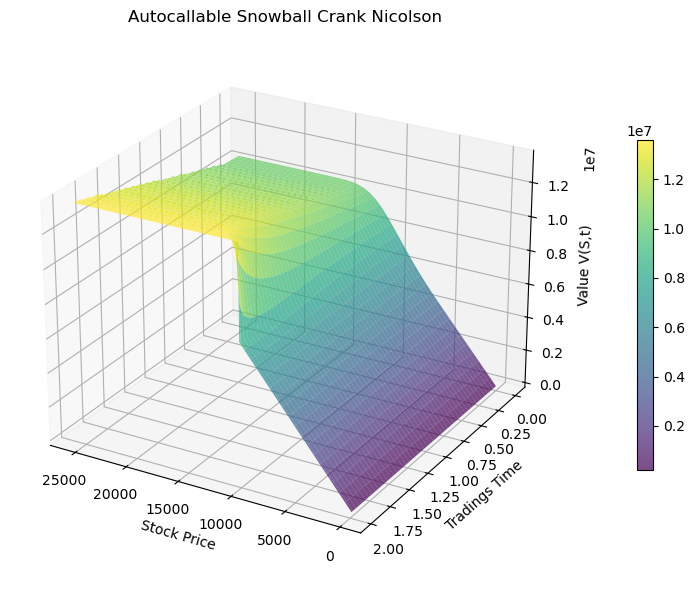

In [15]:
# Construct 3D Mesh
TimeGrid, StockGrid = np.meshgrid(Time, Stock)

# Plot 3D Surface
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(StockGrid,TimeGrid,Surface,cmap='viridis',linewidth=0,antialiased=True,alpha=0.7)

ax.set_xlabel('Stock Price')
ax.set_ylabel('Tradings Time')
ax.set_zlabel('Value V(S,t)')
ax.set_title('Autocallable Snowball Crank Nicolson')

ax.view_init(elev=25, azim=120)
fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1)

plt.tight_layout()
plt.show()
